**Persiapan**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**MATERI**

Fungsi $(1+x)^{\frac{1}{2}}$ dapat dinyatakan dalam bentuk deret sebagai berikut:

$(1+x)^{\frac{1}{2}} = 1 + \frac{1}{2}x\;-\frac{1.1}{2.4}x^{2}\;+\frac{1.1.3}{2.4.6}x^{3}\;-\frac{1.1.3.5}{2.4.6.8}x^{4}+\frac{1.1.3.5.7}{2.4.6.8.10}x^{5} + ... $

Jika kita lihat dengan lebih seksama:

$U_{0}=1$ \\

$U_{1}=\frac{1}{2}x \times U_{0}$ \\

$U_{2}=-\frac{1}{4}x \times U_{1}$ \\

$U_{3}=-\frac{3}{6}x \times U_{2}$ \\

$U_{4}=-\frac{5}{8}x \times U_{3}$ \\

$U_{5}=-\frac{7}{10}x \times U_{4}$ \\

Artinya terdapat rekursi ($n > 0$)

$U_{n}(x) = -\frac{(2n - 3)}{2n}x\;U_{n-1}(x) $





In [2]:
def calculate_term(x, batas, analitik):
    hasil = 1                                      # U0
    U1 = (1/2) * x                                 # U1
    hasil += U1                                    # tambahin suku U1 ke hasil
    tolerance = batas
    i = 1                                          # ini sudah iterasi ke-1
    error = 10
    while abs(error) >= tolerance:
        i += 1                                     # maju hitung suku ke-2
        Ui = -(((2 * i) - 3) * x * U1) / (2 * i)   # tentukan nilai suku selanjutnya
        hasil += Ui                                # tambahin nilai suku selanjutnya ke hasil
        error = abs(Ui / hasil) * 100              # lihat perubahan nilai suku terhadap hasil akhir
        U1 = Ui                                    # persiapan menghitung suku selanjutnya

    return hasil, i

**TRICK**

Deret diatas berlaku untuk $x < 1$, sehingga diperlukan cara untuk mengakali perhitungan, yaitu dengan menggunakan pendekatan bilangan kuadrat.

Misalkan ambil $x=4$, sehingga:

$(1+4)^{\frac{1}{2}} \approx $

Kita tahu bahwa $1 + 4 = 5$, sehingga kita perlu cari nilai bilangan kudrat terdekat diatas $5$, yaitu $9$.

$(1+4)^{\frac{1}{2}} = (5)^{\frac{1}{2}}=\left(9\frac{(9-4)}{9}\right)^{\frac{1}{2}}$ \\

$(1+4)^{\frac{1}{2}} =3 \times \left(1-\frac{4}{9}\right)^{\frac{1}{2}}$



In [7]:
def upper_square(target):
    n = 1                  # mulai dari 1
    while n * n < target:  # cari n hingga n^2 >= target
        n += 1             # naikin nilai n jika belum nemu
    return n*n, n

def trick(x, batas, analitik):
  basis = 1 + x                                       # inisiasi basis
  N, n = upper_square(basis)                          # cari nilai kuadrat terdekat
  x = (basis - N) / N                                 # ubah nilai variabel x
  numeric, term = calculate_term(x, batas, analitik)  # hitung dengan deret
  # print(f'kalikan dengan {N}')
  # print('-------------------')
  numeric = numeric * n                               # koreksi nilai numerik
  return numeric, term

In [4]:
x = float(input("Masukkan nilai x: "))               # input nilai x
batas = float(input("Masukkan batas error (1e): "))  # nilai error perubahan suku
print('==========================================')
analitik = np.sqrt(1 + x)                            # hitung secara analitik
numeric, term = trick(x, batas, analitik)

print(f'Untuk nilai x = {x}')
print(f'Nilai analitik = {analitik}')
print(f'Nilai numerik = {numeric}')
print(f'Jumlah iterasi = {term}')

Masukkan nilai x: 123.43265
Masukkan batas error (1e): 1e-15
kalikan dengan 144
-------------------
Untuk nilai x = 123.43265
Nilai analitik = 11.154938368274385
Nilai numerik = 11.154938368274387
Jumlah iterasi = 17


KURVA

Kurva di set untuk $0 < x < 0.5$ dengan error yang berbeda-beda.

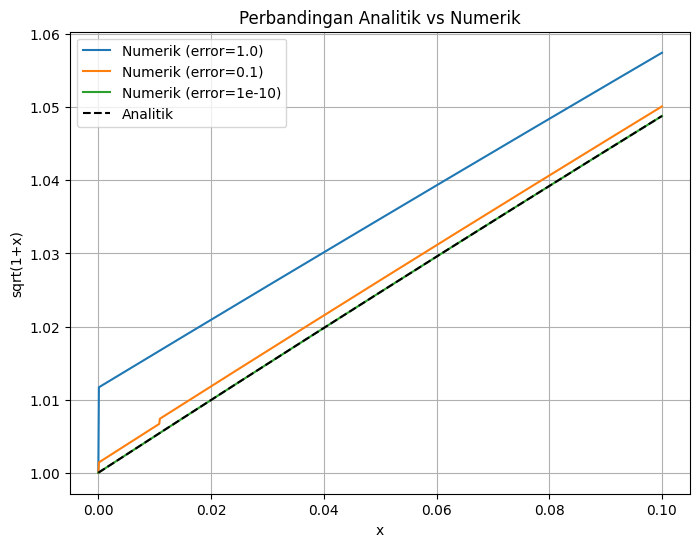

In [8]:
x = np.linspace(0, 0.1, 1000)                           # array x dari 0 hingga 10 dengan 100 titik
y_analitik = np.sqrt(1 + x)                             # perhitungan nilai analitik

error_values = [1e-0, 1e-1, 1e-10]                      # daftar error yang akan diuji
plt.figure(figsize=(8, 6))                              # ukuran grafik

for error in error_values:
    y_numeric = []                                      # simpan hasil numerik untuk setiap error
    for i in x:
        numeric, term = trick(i, error, np.sqrt(1 + i)) # gunakan nilai analitik yang sesuai
        y_numeric.append(numeric)                       # Simpan hasil numerik

    plt.plot(x, y_numeric, label=f'Numerik (error={error})')  # Plot hasil numerik

# Plot analitik sebagai referensi
plt.plot(x, y_analitik, 'k--', label='Analitik')        # plot hasil analitik

plt.xlabel('x')
plt.ylabel('sqrt(1+x)')
plt.title('Perbandingan Analitik vs Numerik')
plt.legend()
plt.grid()
plt.show()

Semakin kecil error yang di set, maka logaritma akan menggunakan semakin banyak suku, sehingga nilai semakin mendekati hasil eksak